In [39]:
%load_ext autoreload
%autoreload 2

import platform
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import matplotlib
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import mutual_info_score

from utils import CAT, CONT, DISC, DUMMY, FEATS, HASH_TEST, HASH_TRAIN, DADOS, RESULTADOS, SEED, sha256, estilo, AZUL, CINZA, TINTA, TINTA_2, DIVERGENTE, VERMELHO

pd.set_option("display.max_columns", 200)
pd.set_option("display.max_rows", 150)

print(f"Python {sys.version.split()[0]} | {platform.platform()}")
for lib in (np, pd, sklearn, matplotlib):
    print(f"{lib.__name__:<12}{lib.__version__}")
print(f"SEED = {SEED} | DADOS = {DADOS}")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Python 3.12.12 | macOS-26.5.1-arm64-arm-64bit
numpy       2.5.5
pandas      3.1.1
sklearn     1.9.1
matplotlib  3.11.2
SEED = 42 | DADOS = /Users/dereo/Workspace/projects/mdc/INF0619-projeto-final/final/dados


In [18]:
estilo()

In [19]:
for nome, esperado in [("train.csv", HASH_TRAIN), ("test.csv", HASH_TEST)]:
    obtido = sha256(DADOS / nome)
    assert obtido == esperado, f"{nome}: {obtido}, esperado {esperado}"
    print(f"{nome}: {obtido} ok")

train.csv: b9d33ee3792f ok
test.csv: beeff8a276c3 ok


In [20]:
treino = pd.read_csv(DADOS / "train.csv")
teste = pd.read_csv(DADOS / "test.csv")

print("train:", treino.shape, "| test:", teste.shape)
print("só no treino:", sorted(set(treino.columns) - set(teste.columns)))
print("só no teste:", sorted(set(teste.columns) - set(treino.columns)))
print("colunas não numéricas:", treino.select_dtypes(exclude="number").columns.tolist())
treino.head()

train: (47504, 128) | test: (11877, 128)
só no treino: ['Response']
só no teste: ['ID']
colunas não numéricas: ['Product_Info_2']


,Id,Product_Info_1,Product_Info_2,Product_Info_3,Product_Info_4,Product_Info_5,Product_Info_6,Product_Info_7,Ins_Age,Ht,Wt,BMI,Employment_Info_1,Employment_Info_2,Employment_Info_3,Employment_Info_4,Employment_Info_5,Employment_Info_6,InsuredInfo_1,InsuredInfo_2,InsuredInfo_3,InsuredInfo_4,InsuredInfo_5,InsuredInfo_6,InsuredInfo_7,Insurance_History_1,Insurance_History_2,Insurance_History_3,Insurance_History_4,Insurance_History_5,Insurance_History_7,Insurance_History_8,Insurance_History_9,Family_Hist_1,Family_Hist_2,Family_Hist_3,Family_Hist_4,Family_Hist_5,Medical_History_1,Medical_History_2,Medical_History_3,Medical_History_4,Medical_History_5,Medical_History_6,Medical_History_7,Medical_History_8,Medical_History_9,Medical_History_10,Medical_History_11,Medical_History_12,Medical_History_13,Medical_History_14,Medical_History_15,Medical_History_16,Medical_History_17,Medical_History_18,Medical_History_19,Medical_History_20,Medical_History_21,Medical_History_22,Medical_History_23,Medical_History_24,Medical_History_25,Medical_History_26,Medical_History_27,Medical_History_28,Medical_History_29,Medical_History_30,Medical_History_31,Medical_History_32,Medical_History_33,Medical_History_34,Medical_History_35,Medical_History_36,Medical_History_37,Medical_History_38,Medical_History_39,Medical_History_40,Medical_History_41,Medical_Keyword_1,Medical_Keyword_2,Medical_Keyword_3,Medical_Keyword_4,Medical_Keyword_5,Medical_Keyword_6,Medical_Keyword_7,Medical_Keyword_8,Medical_Keyword_9,Medical_Keyword_10,Medical_Keyword_11,Medical_Keyword_12,Medical_Keyword_13,Medical_Keyword_14,Medical_Keyword_15,Medical_Keyword_16,Medical_Keyword_17,Medical_Keyword_18,Medical_Keyword_19,Medical_Keyword_20,Medical_Keyword_21,Medical_Keyword_22,Medical_Keyword_23,Medical_Keyword_24,Medical_Keyword_25,Medical_Keyword_26,Medical_Keyword_27,Medical_Keyword_28,Medical_Keyword_29,Medical_Keyword_30,Medical_Keyword_31,Medical_Keyword_32,Medical_Keyword_33,Medical_Keyword_34,Medical_Keyword_35,Medical_Keyword_36,Medical_Keyword_37,Medical_Keyword_38,Medical_Keyword_39,Medical_Keyword_40,Medical_Keyword_41,Medical_Keyword_42,Medical_Keyword_43,Medical_Keyword_44,Medical_Keyword_45,Medical_Keyword_46,Medical_Keyword_47,Medical_Keyword_48,Response
0,3633,1,D2,26,0.282051,2,3,1,0.507463,0.872727,0.301255,0.339672,0.0750,9,1,0.0,2,NaN,1,2,8,3,1,1,1,2,1,1,3,NaN,3,2,3,2,NaN,0.598039,NaN,0.196429,1.0,491,2,2,1,3,2,2,2,NaN,3,2,3,3,NaN,1,3,2,1,2,1,2,3,NaN,1,3,3,1,3,2,3,NaN,3,3,1,2,2,1,3,3,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2
1,39326,1,D1,26,0.076923,2,3,1,0.477612,0.727273,0.269874,0.415192,0.0205,9,1,0.0,2,NaN,1,2,8,3,1,1,1,1,1,3,1,0.000667,1,1,2,2,NaN,0.441176,0.577465,NaN,7.0,112,2,1,1,3,2,3,1,NaN,3,2,1,3,0.0,1,3,1,1,2,2,2,3,NaN,1,3,3,1,3,2,3,NaN,3,3,1,2,2,1,3,3,3,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,3
2,58070,2,D4,26,0.384615,2,3,1,0.298507,0.727273,0.332636,0.519880,0.0300,12,1,0.0,2,0.25,1,2,8,2,1,2,1,2,1,1,3,NaN,3,2,3,3,NaN,0.098039,0.323944,NaN,4.0,42,2,2,1,3,2,2,1,NaN,3,2,1,3,NaN,1,3,1,1,2,1,1,3,NaN,2,2,3,2,1,2,3,NaN,3,3,1,3,1,1,3,3,3,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,1,0,6
3,3496,1,D4,26,1.000000,2,3,1,0.208955,0.745455,0.236402,0.344016,0.0600,9,1,0.0,2,0.10,2,2,3,3,1,1,1,2,1,1,3,NaN,3,2,3,3,0.318841,NaN,0.253521,NaN,5.0,16,2,2,1,3,2,2,2,NaN,3,2,3,3,NaN,1,3,1,1,2,1,2,3,NaN,1,3,3,1,3,2,3,NaN,3,3,1,2,2,1,3,3,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,8
4,19659,1,D2,26,0.230769,2,1,1,0.537313,0.745455,0.246862,0.360969,0.0850,9,1,0.0,2,0.25,1,2,3,3,1,1,1,1,1,3,1,0.001333,1,1,2,3,0.666667,NaN,0.605634,NaN,0.0,160,2,1,1,3,2,3,2,240.0,3,2,3,3,NaN,1,3,1,1,2,1,2,1,NaN,1,3,3,1,1,2,3,NaN,3,3,1,2,2,1,3,3,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,8


In [21]:
grupos = {"categóricas": CAT, "contínuas": CONT, "discretas": DISC, "dummies": DUMMY}
todas = [c for g in grupos.values() for c in g]

assert len(todas) == len(set(todas)) == 126, "coluna repetida ou faltando"
assert set(todas) == set(treino.columns) - {"Id", "Response"}

pd.Series({k: len(v) for k, v in grupos.items()}, name="colunas")

categóricas    60
contínuas      13
discretas       5
dummies        48
Name: colunas, dtype: int64

In [22]:
dup = treino.duplicated(subset=FEATS, keep=False)
conflitos = treino[dup].groupby(FEATS, dropna=False)["Response"].nunique()

print("linhas repetidas (além da primeira de cada grupo):", treino.duplicated(subset=FEATS).sum())
print("grupos com Response diferente entre si:", int((conflitos > 1).sum()), "de", len(conflitos))

linhas repetidas (além da primeira de cada grupo): 17
grupos com Response diferente entre si: 0 de 16


In [23]:
caminho_folds = DADOS / "folds.csv"

if caminho_folds.exists():
    folds = pd.read_csv(caminho_folds)
    print("folds.csv já existe: lido, não regerado")
else:
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    fold = np.empty(len(treino), dtype=int)
    for k, (_, idx_val) in enumerate(skf.split(treino, treino["Response"])):
        fold[idx_val] = k
    folds = pd.DataFrame({"Id": treino["Id"], "fold": fold})
    folds.to_csv(caminho_folds, index=False)
    print("folds.csv gerado")

print("hash:", sha256(caminho_folds))

folds.csv já existe: lido, não regerado
hash: 9ea76b467f2a


In [24]:
assert len(folds) == len(treino) == 47_504
assert folds["Id"].is_unique and set(folds["Id"]) == set(treino["Id"])

tab = treino[["Id", "Response"]].merge(folds, on="Id")
contagem = pd.crosstab(tab["fold"], tab["Response"])
prop_fold = pd.crosstab(tab["fold"], tab["Response"], normalize="index")
prop_total = tab["Response"].value_counts(normalize=True).sort_index()
maior_dif = (prop_fold - prop_total).abs().max().max() * 100

print("linhas por fold:", contagem.sum(axis=1).tolist())
print("classe 3 por fold:", contagem[3].tolist())
print(f"maior diferença de proporção entre fold e total: {maior_dif:.3f} p.p.")
assert maior_dif <= 0.1

linhas por fold: [9501, 9501, 9501, 9501, 9500]
classe 3 por fold: [161, 161, 162, 161, 161]
maior diferença de proporção entre fold e total: 0.009 p.p.


In [25]:
contagem = treino["Response"].value_counts().sort_index()
alvo = pd.DataFrame({
    "linhas": contagem,
    "%": (contagem / contagem.sum() * 100).round(1),
})
alvo

,linhas,%
Response,,
1,4909,10.3
2,5242,11.0
3,806,1.7
4,1144,2.4
5,4313,9.1
6,8984,18.9
7,6469,13.6
8,15637,32.9


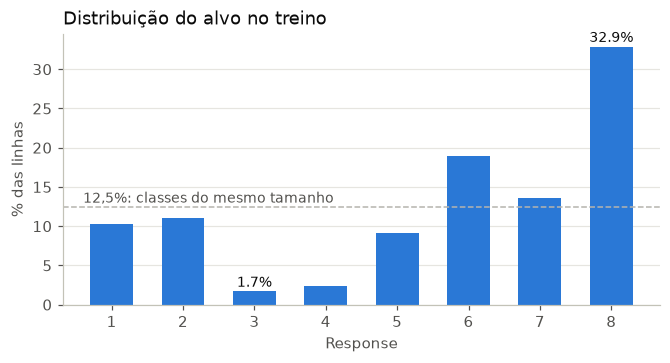

In [26]:
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.bar(alvo.index, alvo["%"], color=AZUL, width=0.6)

# referência: quanto cada classe teria se fossem todas do mesmo tamanho
ax.axhline(100 / 8, color=CINZA, linestyle="--", linewidth=1)
ax.text(0.6, 100 / 8 + 0.5, "12,5%: classes do mesmo tamanho", color=TINTA_2, fontsize=9)

# rótulo só nos extremos; os números exatos estão na tabela
for k in (alvo["%"].idxmin(), alvo["%"].idxmax()):
    ax.annotate(f"{alvo.loc[k, '%']:.1f}%", (k, alvo.loc[k, "%"]),
                xytext=(0, 3), textcoords="offset points", ha="center", color=TINTA, fontsize=9)

ax.set_xticks(alvo.index)
ax.set_xlabel("Response")
ax.set_ylabel("% das linhas")
ax.set_title("Distribuição do alvo no treino", loc="left")
plt.show()

In [27]:
grupo_de = {c: g for g, cols in grupos.items() for c in cols}

visao = pd.DataFrame({
    "grupo": pd.Series(grupo_de),
    "tipo": treino[FEATS].dtypes.astype(str),
    "% NA": treino[FEATS].isna().mean() * 100,
    "distintos": treino[FEATS].nunique(),
    "% valor dominante": treino[FEATS].apply(
        lambda s: s.value_counts(normalize=True, dropna=False).iloc[0] * 100
    ),
}).loc[FEATS]

visao.round(1)

,grupo,tipo,% NA,distintos,% valor dominante
Product_Info_1,categóricas,int64,0.0,2,97.4
Product_Info_2,categóricas,str,0.0,19,24.1
Product_Info_3,categóricas,int64,0.0,30,85.9
Product_Info_5,categóricas,int64,0.0,2,99.3
Product_Info_6,categóricas,int64,0.0,2,83.7
Product_Info_7,categóricas,int64,0.0,3,97.8
Employment_Info_2,categóricas,int64,0.0,33,58.0
Employment_Info_3,categóricas,int64,0.0,2,84.9
Employment_Info_5,categóricas,int64,0.0,2,85.9
InsuredInfo_1,categóricas,int64,0.0,3,79.5


In [28]:
resumo = visao.groupby("grupo", sort=False).agg(
    colunas=("tipo", "size"),
    com_NA=("% NA", lambda x: int((x > 0).sum())),
    quase_constantes=("% valor dominante", lambda x: int((x >= 99).sum())),
    distintos_max=("distintos", "max"),
)
resumo

,colunas,com_NA,quase_constantes,distintos_max
grupo,,,,
categóricas,60,0,8,551
contínuas,13,8,0,3078
discretas,5,5,1,241
dummies,48,0,14,2


In [29]:
cols_na = visao.index[visao["% NA"] > 0]

linhas = []
for c in cols_na:
    na = treino[c].isna()
    linhas.append({
        "coluna": c,
        "% NA": na.mean() * 100,
        "Response médio (NA)": treino.loc[na, "Response"].mean(),
        "Response médio (preenchida)": treino.loc[~na, "Response"].mean(),
        "corr indicador NA": na.astype(int).corr(treino["Response"], method="spearman"),
        "corr valor": treino.loc[~na, c].corr(treino.loc[~na, "Response"], method="spearman"),
    })

ausencia = pd.DataFrame(linhas).set_index("coluna").sort_values("% NA", ascending=False)
ausencia.round(3)

,% NA,Response médio (NA),Response médio (preenchida),corr indicador NA,corr valor
coluna,,,,,
Medical_History_10,99.074,5.656,4.643,0.046,0.048
Medical_History_32,98.148,5.668,4.512,0.084,0.060
Medical_History_24,93.626,5.682,5.124,0.073,0.137
Medical_History_15,75.053,5.957,4.712,0.234,0.320
Family_Hist_5,70.436,5.903,5.035,0.168,-0.010
Family_Hist_3,57.644,5.959,5.222,0.159,0.001
Family_Hist_2,48.280,5.210,6.054,-0.182,-0.063
Insurance_History_5,42.655,5.609,5.675,0.001,0.140
Family_Hist_4,32.246,5.039,5.936,-0.177,-0.097


In [30]:
cols = ausencia.index[ausencia["% NA"] >= 1]  # tira a Employment_Info_1, com NA raro demais

def dif_classes(c):
    """Pontos percentuais de cada classe: linhas com a coluna vazia menos linhas preenchidas."""
    prop = pd.crosstab(treino[c].isna(), treino["Response"], normalize="index") * 100
    return prop.loc[True] - prop.loc[False]

dif = pd.DataFrame({c: dif_classes(c) for c in cols}).T
dif.round(1)

Response,1,2,3,4,5,6,7,8
Medical_History_10,-8.4,-2.9,-0.1,0.8,-0.9,-15.3,5.3,21.5
Medical_History_32,-3.0,-1.7,-3.2,-4.8,0.5,-30.7,11.7,31.5
Medical_History_24,-1.0,-3.1,-0.8,-0.5,-0.5,-12.6,1.9,16.4
Medical_History_15,-6.4,-3.4,-5.8,-8.3,1.4,-2.4,3.5,21.5
Family_Hist_5,-8.0,-4.5,0.2,0.9,-1.0,-0.7,-3.8,17.0
Family_Hist_3,-6.0,-4.6,0.2,1.0,-0.4,-2.4,-3.8,15.9
Family_Hist_2,7.0,4.9,-0.1,-0.9,1.4,1.6,3.2,-17.0
Insurance_History_5,1.5,-0.4,1.0,0.7,0.4,-3.2,-3.9,3.9
Family_Hist_4,8.3,4.6,-0.2,-0.8,1.3,0.6,3.4,-17.1
Employment_Info_6,0.3,-0.3,0.4,0.9,2.6,-4.2,-0.9,1.1


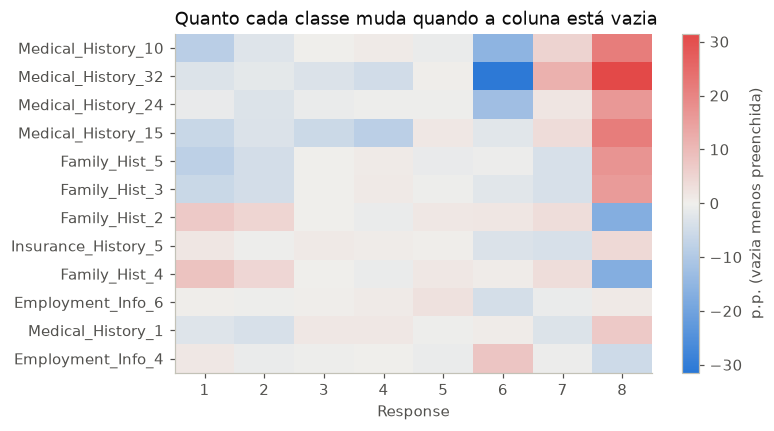

In [31]:
lim = dif.abs().max().max()  # escala simétrica: zero fica no cinza

fig, ax = plt.subplots(figsize=(7, 4))
im = ax.imshow(dif, cmap=DIVERGENTE, vmin=-lim, vmax=lim, aspect="auto")
ax.set_xticks(range(8), dif.columns)
ax.set_yticks(range(len(dif)), dif.index)
ax.set_xlabel("Response")
ax.grid(False)
fig.colorbar(im, ax=ax, label="p.p. (vazia menos preenchida)")
ax.set_title("Quanto cada classe muda quando a coluna está vazia", loc="left")
plt.show()

In [32]:
num = CONT + DISC

desc = treino[num].describe().T[["count", "min", "50%", "max"]]
desc["distintos"] = treino[num].nunique()
desc["% no valor mais comum"] = treino[num].apply(lambda s: s.value_counts(normalize=True).iloc[0] * 100)
desc["valor mais comum"] = treino[num].mode().iloc[0]
desc["assimetria"] = treino[num].skew()
desc.round(3)

,count,min,50%,max,distintos,% no valor mais comum,valor mais comum,assimetria
Product_Info_4,47504.0,0.000,0.231,1.000,1223,22.272,0.077,1.220
Ins_Age,47504.0,0.000,0.403,1.000,65,2.650,0.537,0.019
Ht,47504.0,0.091,0.709,1.000,37,9.001,0.745,-0.076
Wt,47504.0,0.000,0.289,1.000,294,4.134,0.289,0.693
BMI,47504.0,0.000,0.451,1.000,3078,0.581,0.429,0.943
Employment_Info_1,47492.0,0.000,0.060,1.000,1668,6.239,0.000,4.716
Employment_Info_4,42106.0,0.000,0.000,1.000,748,84.891,0.000,15.372
Employment_Info_6,38877.0,0.000,0.250,1.000,882,15.806,1.000,0.783
Insurance_History_5,27241.0,0.000,0.001,0.492,1925,15.792,0.001,88.099
Family_Hist_2,24569.0,0.000,0.464,1.000,68,4.453,0.435,0.218


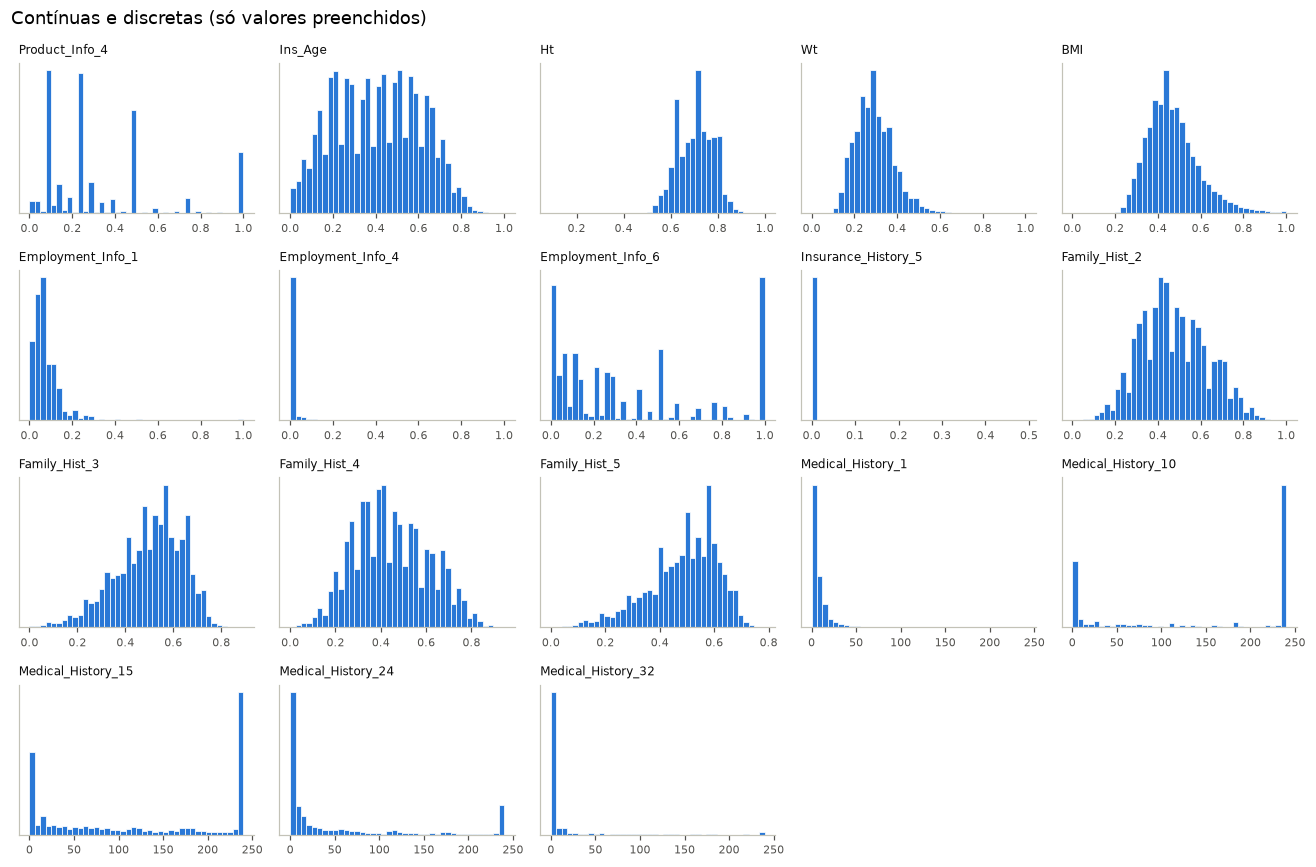

In [33]:
fig, axes = plt.subplots(4, 5, figsize=(12, 8))  # 18 colunas, sobram 2 eixos

for ax, c in zip(axes.flat, num):
    ax.hist(treino[c].dropna(), bins=40, color=AZUL, edgecolor="white", linewidth=0.5)
    ax.set_title(c, fontsize=8, loc="left")
    ax.tick_params(labelsize=7)
    ax.set_yticks([])

for ax in axes.flat[len(num):]:
    ax.set_visible(False)

fig.suptitle("Contínuas e discretas (só valores preenchidos)", x=0.01, ha="left")
fig.tight_layout()
plt.show()

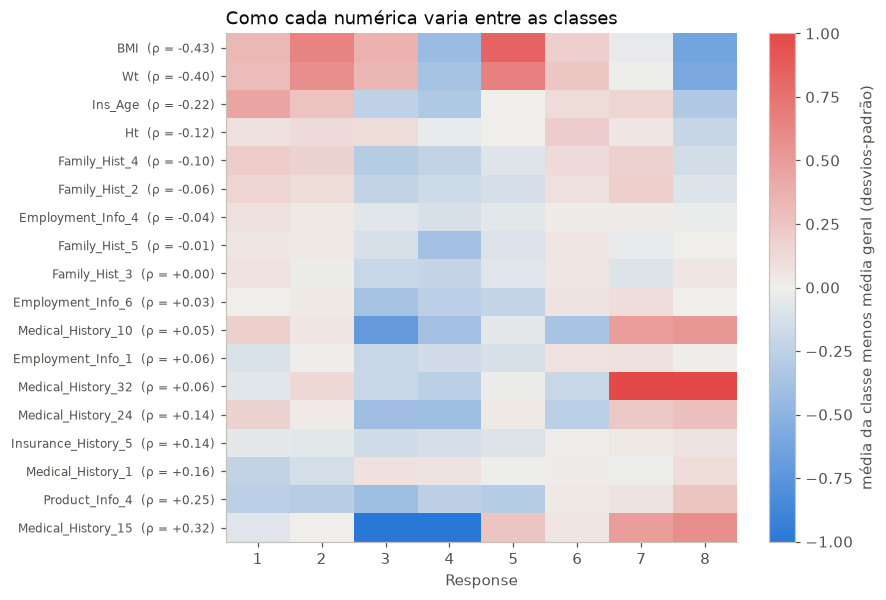

In [34]:
media_classe = treino.groupby("Response")[num].mean().T  # linhas: colunas; colunas: classes
desvio = media_classe.sub(treino[num].mean(), axis=0).div(treino[num].std(), axis=0)

spearman = pd.Series({
    c: treino[[c, "Response"]].dropna().corr(method="spearman").iloc[0, 1] for c in num
})
ordem = spearman.sort_values().index

lim = 1.0  # valores além de ±1 desvio saturam a cor
fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(desvio.loc[ordem], cmap=DIVERGENTE, vmin=-lim, vmax=lim, aspect="auto")
ax.set_xticks(range(8), desvio.columns)
ax.set_yticks(range(len(ordem)), [f"{c}  (ρ = {spearman[c]:+.2f})" for c in ordem], fontsize=8)
ax.set_xlabel("Response")
ax.grid(False)
fig.colorbar(im, ax=ax, label="média da classe menos média geral (desvios-padrão)")
ax.set_title("Como cada numérica varia entre as classes", loc="left")
plt.show()

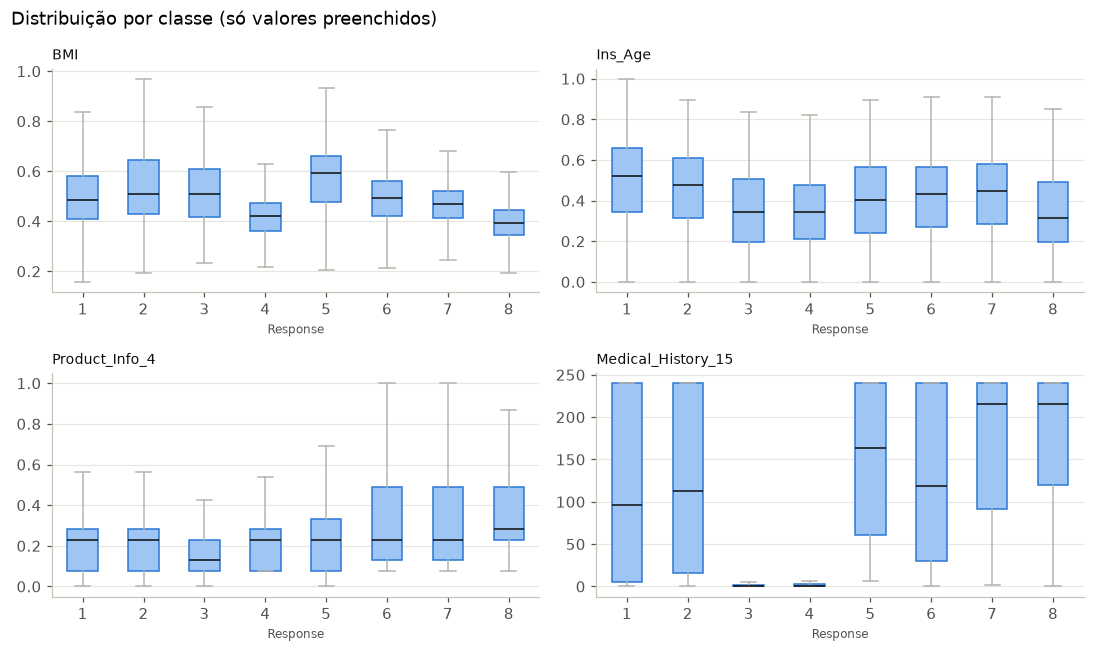

In [35]:
destaques = ["BMI", "Ins_Age", "Product_Info_4", "Medical_History_15"]

fig, axes = plt.subplots(2, 2, figsize=(10, 6))
for ax, c in zip(axes.flat, destaques):
    grupos_classe = [treino.loc[treino["Response"] == k, c].dropna() for k in range(1, 9)]
    ax.boxplot(grupos_classe, tick_labels=range(1, 9), showfliers=False, patch_artist=True,
               boxprops=dict(facecolor="#9ec5f4", edgecolor=AZUL),
               medianprops=dict(color=TINTA),
               whiskerprops=dict(color=CINZA), capprops=dict(color=CINZA))
    ax.set_title(c, loc="left", fontsize=9)
    ax.set_xlabel("Response", fontsize=8)

fig.suptitle("Distribuição por classe (só valores preenchidos)", x=0.01, ha="left")
fig.tight_layout()
plt.show()

In [36]:
n = len(treino)
linhas = []
for c in CAT:
    vc = treino[c].value_counts()
    raras = vc[vc < 0.01 * n]
    linhas.append({
        "coluna": c,
        "distintos": len(vc),
        "% categoria dominante": vc.iloc[0] / n * 100,
        "categorias raras (< 1%)": len(raras),
        "% linhas em raras": raras.sum() / n * 100,
    })

card = pd.DataFrame(linhas).set_index("coluna").sort_values("distintos", ascending=False)
card.round(2)

,distintos,% categoria dominante,categorias raras (< 1%),% linhas em raras
coluna,,,,
Medical_History_2,551,18.49,535,22.62
Employment_Info_2,33,58.03,28,2.71
Product_Info_3,30,85.85,27,1.95
Product_Info_2,19,24.10,6,2.07
InsuredInfo_3,11,31.58,3,1.16
Medical_History_18,3,94.68,1,0.01
Medical_History_21,3,88.99,1,0.01
Medical_History_20,3,98.49,1,0.00
Medical_History_19,3,96.53,1,0.01


In [37]:
card["distintos"].value_counts().sort_index().rename("colunas")

distintos
2      16
3      39
11      1
19      1
30      1
33      1
551     1
Name: colunas, dtype: int64

In [38]:
pi2 = treino["Product_Info_2"].value_counts().sort_index()
pd.DataFrame({"linhas": pi2, "letra": pi2.index.str[0], "número": pi2.index.str[1]})

,linhas,letra,número
Product_Info_2,,,
A1,1901,A,1
A2,1543,A,2
A3,771,A,3
A4,161,A,4
A5,605,A,5
A6,1688,A,6
A7,1107,A,7
A8,5488,A,8
B1,43,B,1


In [40]:
y = treino["Response"]
rng = np.random.default_rng(SEED)
y_embaralhados = [rng.permutation(y.to_numpy()) for _ in range(5)]
H_y = mutual_info_score(y, y)  # entropia do Response: o teto da MI

linhas = []
for c in CAT:
    x = treino[c]
    mi = mutual_info_score(x, y)
    acaso = np.mean([mutual_info_score(x, ye) for ye in y_embaralhados])
    linhas.append({
        "coluna": c,
        "distintos": x.nunique(),
        "MI": mi,
        "MI do acaso": acaso,
        "MI líquida": mi - acaso,
        "% de H(Response)": (mi - acaso) / H_y * 100,
    })

mi_cat = pd.DataFrame(linhas).set_index("coluna").sort_values("MI líquida", ascending=False)
print(f"H(Response) = {H_y:.3f} nats")
mi_cat.head(15).round(4)

H(Response) = 1.807 nats


,distintos,MI,MI do acaso,MI líquida,% de H(Response)
coluna,,,,,
Medical_History_23,3,0.0752,0.0001,0.0751,4.1570
Medical_History_4,2,0.0751,0.0000,0.0751,4.1549
Product_Info_2,19,0.0689,0.0014,0.0675,3.7370
Medical_History_39,3,0.0266,0.0001,0.0265,1.4640
Medical_History_2,551,0.0594,0.0333,0.0261,1.4462
InsuredInfo_6,2,0.0223,0.0001,0.0222,1.2292
Medical_History_6,3,0.0153,0.0001,0.0152,0.8386
Employment_Info_2,33,0.0155,0.0022,0.0133,0.7363
Medical_History_16,2,0.0112,0.0001,0.0111,0.6160


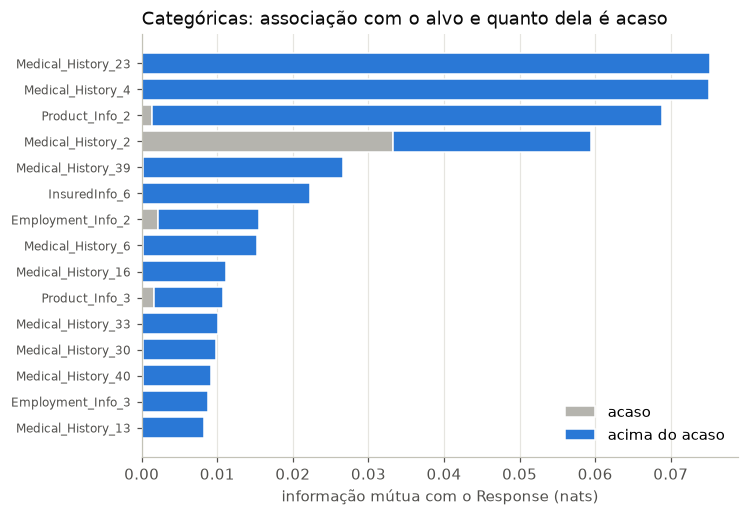

In [41]:
top = mi_cat.sort_values("MI", ascending=False).head(15).iloc[::-1]  # invertido: a maior fica em cima

fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(top.index, top["MI do acaso"], color=CINZA, edgecolor="white", label="acaso")
ax.barh(top.index, top["MI líquida"], left=top["MI do acaso"], color=AZUL, edgecolor="white",
        label="acima do acaso")
ax.set_xlabel("informação mútua com o Response (nats)")
ax.tick_params(axis="y", labelsize=8)
ax.grid(False)
ax.grid(axis="x")
ax.legend(frameon=False, loc="lower right")
ax.set_title("Categóricas: associação com o alvo e quanto dela é acaso", loc="left")
plt.show()

In [42]:
prev = treino[DUMMY].mean().mul(100).sort_values(ascending=False)
print(prev.describe().round(2))
prev.head(8).round(1)

count    48.00
mean      2.64
std       3.25
min       0.59
25%       0.93
50%       1.35
75%       2.79
max      19.05
dtype: float64


Medical_Keyword_15    19.0
Medical_Keyword_23     9.7
Medical_Keyword_25     9.1
Medical_Keyword_37     6.6
Medical_Keyword_11     5.8
Medical_Keyword_40     5.7
Medical_Keyword_48     5.4
Medical_Keyword_3      5.0
dtype: float64

In [43]:
soma_kw = treino[DUMMY].sum(axis=1)
print(f"linhas sem nenhuma keyword: {(soma_kw == 0).mean():.1%}")
print("distribuição da soma:", soma_kw.value_counts().sort_index().to_dict())

por_classe = pd.DataFrame({
    "média de keywords": soma_kw.groupby(treino["Response"]).mean(),
    "% com alguma": (soma_kw > 0).groupby(treino["Response"]).mean() * 100,
}).round(2)
por_classe

linhas sem nenhuma keyword: 39.6%
distribuição da soma: {0: 18814, 1: 12871, 2: 7572, 3: 4191, 4: 2170, 5: 1056, 6: 485, 7: 214, 8: 72, 9: 41, 10: 13, 11: 2, 12: 1, 14: 1, 16: 1}


,média de keywords,% com alguma
Response,,
1,2.15,81.26
2,1.93,77.55
3,1.26,66.75
4,0.95,55.68
5,1.43,65.87
6,1.36,65.64
7,1.30,64.32
8,0.67,41.96


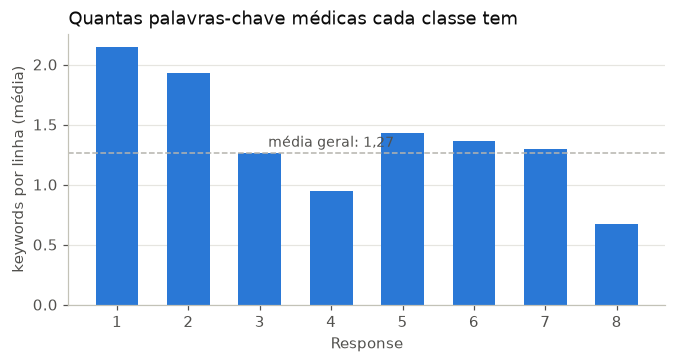

In [46]:
media_geral = soma_kw.mean()

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.bar(por_classe.index, por_classe["média de keywords"], color=AZUL, width=0.6)
ax.axhline(media_geral, color=CINZA, linestyle="--", linewidth=1)
ax.text(4, media_geral + 0.05, f"média geral: {media_geral:.2f}".replace(".", ","),
        color=TINTA_2, fontsize=9, ha="center")
ax.set_xticks(por_classe.index)
ax.set_xlabel("Response")
ax.set_ylabel("keywords por linha (média)")
ax.set_title("Quantas palavras-chave médicas cada classe tem", loc="left")
plt.show()

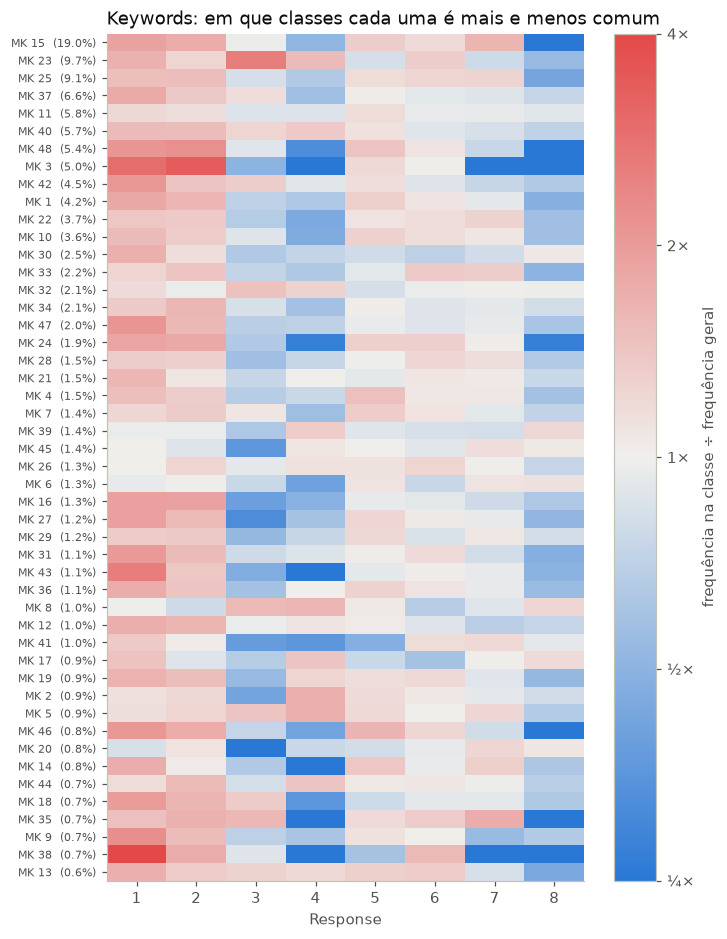

In [45]:
taxa_classe = treino.groupby("Response")[DUMMY].mean()    # P(keyword = 1 | classe)
lift = taxa_classe.div(treino[DUMMY].mean(), axis=1).T   # linhas: keywords; colunas: classes
log_lift = np.log2(lift.clip(lower=1 / 16))              # 0 vira 1/16, pra não dar -infinito
ordem_kw = prev.index                                     # mais comuns em cima

fig, ax = plt.subplots(figsize=(7, 10))
im = ax.imshow(log_lift.loc[ordem_kw], cmap=DIVERGENTE, vmin=-2, vmax=2, aspect="auto")
ax.set_xticks(range(8), taxa_classe.index)
ax.set_yticks(range(len(ordem_kw)),
              [f"{k.replace('Medical_Keyword_', 'MK ')}  ({prev[k]:.1f}%)" for k in ordem_kw], fontsize=7)
ax.set_xlabel("Response")
ax.grid(False)
cb = fig.colorbar(im, ax=ax, ticks=[-2, -1, 0, 1, 2])
cb.ax.set_yticklabels(["¼×", "½×", "1×", "2×", "4×"])
cb.set_label("frequência na classe ÷ frequência geral")
ax.set_title("Keywords: em que classes cada uma é mais e menos comum", loc="left")
plt.show()

In [47]:
pares = [("Family_Hist_2", "Family_Hist_3"), ("Family_Hist_4", "Family_Hist_5")]

for a, b in pares:
    display(pd.crosstab(treino[a].notna().rename(f"{a} preenchida"),
                        treino[b].notna().rename(f"{b} preenchida")))

Family_Hist_3 preenchida,False,True
Family_Hist_2 preenchida,,
False,2814,20121
True,24569,0


Family_Hist_5 preenchida,False,True
Family_Hist_4 preenchida,,
False,1274,14044
True,32186,0


In [48]:
fh = [c for par in pares for c in par]

linhas = []
for c in fh:
    m = treino[c].notna()
    x, v = treino.loc[m, "Ins_Age"], treino.loc[m, c]
    linhas.append({
        "coluna": c,
        "preenchida (%)": m.mean() * 100,
        "Ins_Age média do proponente": x.mean(),
        "inclinação contra Ins_Age": np.polyfit(x, v, 1)[0],
        "corr com Ins_Age": v.corr(x),
    })

display(pd.DataFrame(linhas).set_index("coluna").round(2))
print("corr 2 × 4:", round(treino["Family_Hist_2"].corr(treino["Family_Hist_4"]), 2))
print("corr 3 × 5:", round(treino["Family_Hist_3"].corr(treino["Family_Hist_5"]), 2))

,preenchida (%),Ins_Age média do proponente,inclinação contra Ins_Age,corr com Ins_Age
coluna,,,,
Family_Hist_2,51.72,0.30,0.85,0.86
Family_Hist_3,42.36,0.54,0.32,0.36
Family_Hist_4,67.75,0.33,0.86,0.90
Family_Hist_5,29.56,0.57,0.42,0.48


corr 2 × 4: 0.93
corr 3 × 5: 0.21


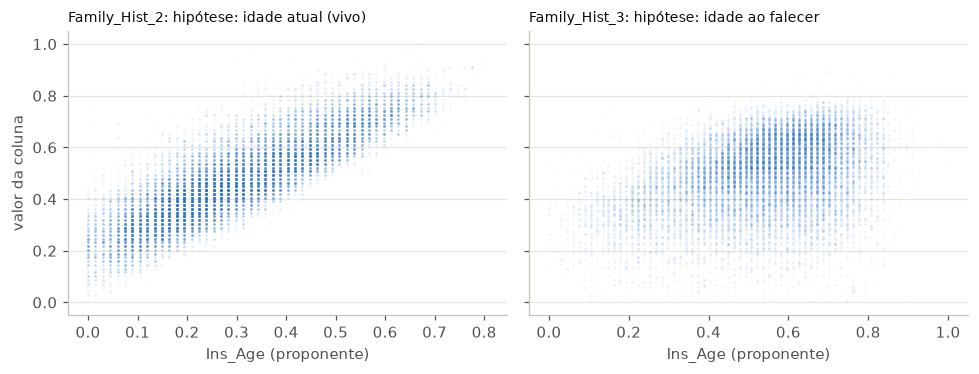

In [49]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5), sharey=True)
for ax, c, rotulo in zip(axes, ["Family_Hist_2", "Family_Hist_3"],
                         ["hipótese: idade atual (vivo)", "hipótese: idade ao falecer"]):
    m = treino[c].notna()
    ax.scatter(treino.loc[m, "Ins_Age"], treino.loc[m, c], s=3, alpha=0.05, color=AZUL, linewidths=0)
    ax.set_xlabel("Ins_Age (proponente)")
    ax.set_title(f"{c}: {rotulo}", loc="left", fontsize=9)
axes[0].set_ylabel("valor da coluna")
fig.tight_layout()
plt.show()

In [50]:
n_vivos = treino["Family_Hist_2"].notna().astype(int) + treino["Family_Hist_4"].notna().astype(int)
n_vivos = n_vivos.rename("pais vivos")
faixa_idade = pd.qcut(treino["Ins_Age"], 4, labels=["Q1 (mais jovens)", "Q2", "Q3", "Q4 (mais velhos)"])

display(pd.crosstab(faixa_idade, n_vivos))
display(pd.crosstab(faixa_idade, n_vivos, values=treino["Response"], aggfunc="mean").round(2))
(pd.crosstab(n_vivos, treino["Response"], normalize="index") * 100).round(1)

pais vivos,0,1,2
Ins_Age,,,
Q1 (mais jovens),360,1914,10030
Q2,915,3434,7254
Q3,3655,5177,3727
Q4 (mais velhos),7505,2858,675


pais vivos,0,1,2
Ins_Age,,,
Q1 (mais jovens),5.56,5.79,6.33
Q2,5.46,5.68,6.08
Q3,5.20,5.49,5.76
Q4 (mais velhos),4.70,5.27,5.68


Response,1,2,3,4,5,6,7,8
pais vivos,,,,,,,,
0,17.1,14.8,1.5,1.6,10.0,19.7,15.5,19.8
1,10.4,11.9,1.8,2.5,9.6,19.4,15.6,28.9
2,6.4,8.3,1.8,2.8,8.3,18.2,11.3,42.9


In [51]:
quase = visao.index[visao["% valor dominante"] >= 99]

linhas = []
for c in quase:
    x = treino[c].fillna(-1)                    # o NA conta como valor (caso da Medical_History_10)
    minoria = x != x.value_counts().index[0]    # linhas fora do valor dominante
    prop = pd.crosstab(minoria, y, normalize="index") * 100
    dif = prop.loc[True] - prop.loc[False]
    k = dif.abs().idxmax()                      # classe que mais muda na minoria
    acaso = np.mean([mutual_info_score(x, ye) for ye in y_embaralhados])
    linhas.append({
        "coluna": c,
        "linhas na minoria": int(minoria.sum()),
        "% de H(Response)": (mutual_info_score(x, y) - acaso) / H_y * 100,
        "maior desvio (p.p.)": dif[k],
        "classe": k,
    })

quase_tab = (pd.DataFrame(linhas).set_index("coluna")
             .sort_values("maior desvio (p.p.)", key=abs, ascending=False))
quase_tab.round(2)

,linhas na minoria,% de H(Response),maior desvio (p.p.),classe
coluna,,,,
Medical_History_35,53,0.06,46.32,1
Medical_Keyword_38,332,0.32,34.18,1
InsuredInfo_2,363,0.28,-32.62,8
Medical_Keyword_35,337,0.11,-28.97,8
Medical_History_38,230,0.09,-26.09,8
Medical_History_5,347,0.16,26.04,2
Medical_Keyword_46,399,0.11,-25.11,8
Medical_History_27,463,0.18,23.81,1
Medical_History_10,440,0.13,-21.53,8


In [52]:
X_num = treino[FEATS].drop(columns="Product_Info_2")   # a única de texto
corr = X_num.corr()
acima = np.triu(np.ones(corr.shape, dtype=bool), k=1)
pares_corr = corr.where(acima).stack()
redundantes = pares_corr[pares_corr.abs() > 0.9].sort_values(key=abs, ascending=False)
redundantes.round(3)

Medical_History_33   Medical_Keyword_23    -0.993
Medical_History_6    Medical_Keyword_48    -0.993
Medical_History_25   Medical_History_26    -0.988
Insurance_History_3  Insurance_History_9   -0.983
                     Insurance_History_7   -0.975
Medical_History_26   Medical_History_36    -0.967
Insurance_History_7  Insurance_History_9    0.962
Medical_History_25   Medical_History_36     0.955
Medical_History_37   Medical_Keyword_11    -0.949
Insurance_History_3  Insurance_History_4   -0.949
Insurance_History_4  Insurance_History_9    0.938
Family_Hist_2        Family_Hist_4          0.934
Insurance_History_4  Insurance_History_7    0.919
dtype: float64

In [53]:
pd.crosstab(treino["Medical_History_33"], treino["Medical_Keyword_23"])

Medical_Keyword_23,0,1
Medical_History_33,,
1,26,4572
3,42873,33


### 3.9 Resumo: achado → o que muda no `02` → experimento

| # | Achado (seção) | O que vira no `02_modeling` | Experimento | Prioridade |
|---|---|---|---|---|
| 1 | 17 linhas duplicadas, todas com o mesmo `Response` (2.4) | Remover no treino, fora da `prepara()`; o teste não perde linha | preparação (seção 4) | obrigatório |
| 2 | Alvo desbalanceado: 3 e 4 somam ~4% das linhas e valem 2/8 da métrica (3.1) | Tratamento do desbalanceamento: `class_weight`, probabilidade ÷ frequência, class weights nas probabilidades (aprendidos dentro do fold) | E01 | obrigatório |
| 3 | NA só nas numéricas; a ausência carrega sinal (`Medical_History_15` vazia quase elimina 3 e 4) (3.3) | Bloco A: indicadores de NA e contagem de NA por grupo. Ganho esperado maior na logística; as árvores já usam o NaN nativamente | E04 | obrigatório |
| 4 | Picos em 0 e 240 nas `Medical_History` discretas; zeros e teto nas `Employment_Info` (3.4) | Bloco C: indicadores `== 0` e `== 240` | E06 | se der tempo |
| 5 | Contínuas já normalizadas; assimetria forte em algumas (3.4) | Só no pipeline da logística: `log1p` ou `QuantileTransformer` e `StandardScaler` | E02 | obrigatório |
| 6 | Relações não monotônicas (pico de `BMI` na classe 5); 3 e 4 parecidas, diferem pelo peso; 1 e 2 sem marca forte nas numéricas (3.4) | Modelos que capturam não monotonia (árvores). Na matriz de confusão do E00, esperar confusão 3 ↔ 4 e recall baixo em 1 e 2 | E00, E02 | obrigatório |
| 7 | 55 de 60 categóricas têm 2 ou 3 valores; ternárias com categorias de 1 a 7 linhas (3.5) | Encoding só pesa em 5 colunas; no one-hot, `handle_unknown` e `min_frequency` | E03 | obrigatório |
| 8 | `Medical_History_2`: 551 categorias, 535 raras; 56% da informação mútua é acaso (3.5) | Frequency ou target encoding dentro do fold; não cabe no encoding nativo do HGB (máximo de 255) | E03 | obrigatório |
| 9 | `Product_Info_2` = família (letra) + subtipo (número) (3.5) | Manter a combinação e acrescentar a letra; variante com letra e número separados | E03 | obrigatório |
| 10 | Keywords: a soma por linha separa 1 e 2 (mais) de 8 (menos); quase não se correlacionam entre si (3.6) | Bloco B: soma e "tem alguma"; PCA como teste barato, com expectativa baixa | E05 | obrigatório |
| 11 | Pares `Family_Hist` = pai vivo ou falecido; o número de pais vivos importa mesmo dentro de cada faixa de idade (3.7) | Bloco E: pares unidos com a origem (vivo, falecido, desconhecido) e número de pais vivos | E07 | **proposta: subir pra obrigatório** |
| 12 | Quase constantes têm sinal concentrado nas classes 1 e 2 (3.8) | Não remover por quase constância | (bloco G) | não fazer |
| 13 | Colunas gêmeas e blocos quase redundantes (3.8) | Previsão: manter. Explicabilidade: permutation importance por grupo | `03_analysis` | obrigatório |

**Expectativa para o E00:** balanced accuracy na casa de 0,5 (nenhuma variável explica mais que ~4% da incerteza do alvo sozinha); recall mais baixo nas classes 1 e 2; confusão entre 3 e 4, e entre 7 e 8.